# 🎫 Task 5: Auto-Tag Support Tickets Using LLM
### DevelopersHub Corporation – AI/ML Engineering Advanced Internship

---

## 🎯 Objective

Build a system that **automatically tags/categorises customer support tickets**
using an LLM via **zero-shot** and **few-shot prompt engineering** techniques.

No model training required — the LLM's pre-existing knowledge is leveraged
through carefully designed prompts to classify tickets accurately.

### Approach

| Component | Detail |
|-----------|--------|
| **Model** | Llama-3.3-70B-Versatile via Groq API (free) |
| **Techniques** | Zero-shot · Few-shot · Chain-of-Thought prompting |
| **Tags** | Billing · Technical · Account · Shipping · General |
| **Output** | Primary tag + confidence + reasoning + priority |
| **Evaluation** | Accuracy on labelled test set · confusion matrix · latency |

### Skills Practiced
- ✅ Prompt engineering — zero-shot, few-shot, chain-of-thought
- ✅ LLM API integration (Groq)
- ✅ Structured JSON output from LLMs
- ✅ Evaluation of LLM-based classifiers
- ✅ Batch processing with rate limiting


## 📦 1. Install & Import Libraries

In [5]:
pip install groq pandas numpy matplotlib seaborn scikit-learn jupyter notebook ipykernel

  Using cached pandas-3.0.3-cp314-cp314-win_amd64.whl.metadata (19 kB)
  Using cached matplotlib-3.11.0-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached scikit_learn-1.9.0-cp314-cp314-win_amd64.whl.metadata (11 kB)
  Using cached jupyter-1.1.1-py2.py3-none-any.whl.metadata (2.0 kB)
  Using cached anyio-4.14.0-py3-none-any.whl.metadata (4.6 kB)
  Using cached distro-1.9.0-py3-none-any.whl.metadata (6.8 kB)
  Using cached httpx-0.28.1-py3-none-any.whl.metadata (7.1 kB)
  Using cached pydantic-2.13.4-py3-none-any.whl.metadata (109 kB)
  Using cached sniffio-1.3.1-py3-none-any.whl.metadata (3.9 kB)
  Using cached idna-3.18-py3-none-any.whl.metadata (6.1 kB)
  Using cached certifi-2026.6.17-py3-none-any.whl.metadata (2.5 kB)
  Using cached httpcore-1.0.9-py3-none-any.whl.metadata (21 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
  Using cached pydantic_core-2.46.4-cp314-cp314-win_amd64.whl.metadata 

In [6]:
# !pip install groq pandas numpy matplotlib seaborn

import os, json, time, warnings
warnings.filterwarnings("ignore")

import numpy  as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from groq import Groq
from sklearn.metrics import (accuracy_score, f1_score,
                              confusion_matrix, classification_report)

# ── Plot style ────────────────────────────────────────────────────────────────
plt.rcParams.update({
    "figure.facecolor": "#0d1117", "axes.facecolor": "#161b22",
    "axes.edgecolor"  : "#30363d", "axes.labelcolor": "#e6edf3",
    "xtick.color"     : "#8b949e", "ytick.color"    : "#8b949e",
    "text.color"      : "#e6edf3", "grid.color"     : "#21262d",
    "grid.linestyle"  : "--",      "grid.alpha"     : 0.5,
    "legend.facecolor": "#161b22", "legend.edgecolor": "#30363d",
})
COLORS = ["#58a6ff","#3fb950","#f78166","#d2a8ff","#ffa657"]

print("✅ Libraries imported!")
print(f"   groq    : {__import__('groq').__version__}")
print(f"   pandas  : {pd.__version__}")


✅ Libraries imported!
   groq    : 1.4.0
   pandas  : 3.0.3


## 🔑 2. Groq API Configuration

We use **Llama-3.3-70B-Versatile** via the Groq API (free tier).

**Get your free key:**
1. Go to 👉 https://console.groq.com
2. Sign up → API Keys → Create Key
3. Set environment variable: `GROQ_API_KEY=gsk_...`


In [ ]:
GROQ_API_KEY = os.environ.get("GROQ_API_KEY", "your-groq-api-key-here")
client       = Groq(api_key=GROQ_API_KEY)
MODEL        = "llama-3.3-70b-versatile"

print("✅ Groq API configured!")
print(f"   Model : {MODEL}")
print(f"   Provider : Groq Cloud (free tier)")


✅ Groq API configured!
   Model : llama-3.3-70b-versatile
   Provider : Groq Cloud (free tier)


## 🏷️ 3. Define Tags & Build Support Ticket Dataset

### Tag Categories

| Tag | Description | Examples |
|-----|-------------|---------|
| **Billing** | Payment, invoices, charges, refunds | "I was double charged", "Where is my refund?" |
| **Technical** | Bugs, errors, connectivity, performance | "App keeps crashing", "Cannot login" |
| **Account** | Profile, password, subscription, access | "Change my email", "Cancel subscription" |
| **Shipping** | Delivery, tracking, lost packages | "My order hasn't arrived", "Wrong item sent" |
| **General** | General enquiries, compliments, feedback | "What are your hours?", "Great service!" |

### Priority Levels
- 🔴 **Critical** — service down, data loss, billing fraud
- 🟠 **High** — significant impact on user experience
- 🟡 **Medium** — functionality impaired but workaround exists
- 🟢 **Low** — minor issues, general questions


In [8]:
# ── Tag definitions ───────────────────────────────────────────────────────────
TAGS       = ["Billing", "Technical", "Account", "Shipping", "General"]
PRIORITIES = ["Critical", "High", "Medium", "Low"]

# ── Labelled support ticket dataset (ground truth for evaluation) ──────────────
TICKETS = [
    # Billing
    {"id":"T001", "ticket":"I was charged twice for my subscription this month. Please refund the extra payment immediately.", "label":"Billing"},
    {"id":"T002", "ticket":"My invoice shows an incorrect amount. I should have been billed $29 but was charged $59.", "label":"Billing"},
    {"id":"T003", "ticket":"I cancelled my plan 2 weeks ago but I'm still being charged. This is unacceptable.", "label":"Billing"},
    {"id":"T004", "ticket":"Can you explain the charges on my latest bill? I see a fee I don't recognise.", "label":"Billing"},
    {"id":"T005", "ticket":"How do I update my credit card information for automatic payments?", "label":"Billing"},
    {"id":"T006", "ticket":"I need a receipt for my last three payments for tax purposes.", "label":"Billing"},

    # Technical
    {"id":"T007", "ticket":"The app keeps crashing every time I try to open it on my iPhone. I've tried reinstalling.", "label":"Technical"},
    {"id":"T008", "ticket":"I cannot log into my account. It says invalid password but I'm using the correct one.", "label":"Technical"},
    {"id":"T009", "ticket":"The website is extremely slow and pages take over 30 seconds to load.", "label":"Technical"},
    {"id":"T010", "ticket":"I'm getting a 500 internal server error whenever I try to submit a form.", "label":"Technical"},
    {"id":"T011", "ticket":"My dashboard data hasn't updated in 3 days. The charts show old information.", "label":"Technical"},
    {"id":"T012", "ticket":"The video call feature is not working. No audio comes through on my end.", "label":"Technical"},
    {"id":"T013", "ticket":"I can't upload files larger than 5MB even though my plan allows 50MB.", "label":"Technical"},

    # Account
    {"id":"T014", "ticket":"I need to change the email address associated with my account.", "label":"Account"},
    {"id":"T015", "ticket":"I forgot my password and the reset email is not arriving in my inbox.", "label":"Account"},
    {"id":"T016", "ticket":"Please delete my account and all associated data per GDPR regulations.", "label":"Account"},
    {"id":"T017", "ticket":"I want to upgrade my plan from Basic to Premium. How do I do this?", "label":"Account"},
    {"id":"T018", "ticket":"How do I add a second user to my account? I want to share access with my colleague.", "label":"Account"},
    {"id":"T019", "ticket":"My account has been locked after too many failed login attempts. Please unlock it.", "label":"Account"},

    # Shipping
    {"id":"T020", "ticket":"My order was supposed to arrive 5 days ago and tracking shows it's still in transit.", "label":"Shipping"},
    {"id":"T021", "ticket":"I received the wrong item in my delivery. I ordered the blue model but got red.", "label":"Shipping"},
    {"id":"T022", "ticket":"My package shows as delivered but I never received it. It may have been stolen.", "label":"Shipping"},
    {"id":"T023", "ticket":"I need to change my delivery address. The order was placed 2 hours ago.", "label":"Shipping"},
    {"id":"T024", "ticket":"Can you provide a tracking number for my order placed last Tuesday?", "label":"Shipping"},
    {"id":"T025", "ticket":"One item from my order of 3 products is missing from the package.", "label":"Shipping"},

    # General
    {"id":"T026", "ticket":"What are your customer support hours? I need to speak with someone urgently.", "label":"General"},
    {"id":"T027", "ticket":"I just wanted to say your team was incredibly helpful last week. Great service!", "label":"General"},
    {"id":"T028", "ticket":"Do you offer student discounts or non-profit pricing?", "label":"General"},
    {"id":"T029", "ticket":"I have a suggestion to improve your mobile app — would you like to hear it?", "label":"General"},
    {"id":"T030", "ticket":"Are your services available in Pakistan? I'm interested in signing up.", "label":"General"},
]

df_tickets = pd.DataFrame(TICKETS)

print(f"✅ Dataset created: {len(df_tickets)} labelled support tickets")
print()
print("📊 Class Distribution:")
dist = df_tickets["label"].value_counts()
for tag, cnt in dist.items():
    bar = "█" * cnt
    print(f"   {tag:<12}: {cnt}  {bar}")


✅ Dataset created: 30 labelled support tickets

📊 Class Distribution:
   Technical   : 7  ███████
   Billing     : 6  ██████
   Account     : 6  ██████
   Shipping    : 6  ██████
   General     : 5  █████


## 🎯 4. Technique 1 — Zero-Shot Prompting

**Zero-shot:** We tell the model what tags exist and ask it to classify
without providing any examples. The model relies entirely on its pre-trained
knowledge of language and context.

**Prompt structure:**
```
[System] You are a support ticket classifier. Tags: Billing, Technical, Account, Shipping, General.
[User]   Classify this ticket. Return JSON only.
         Ticket: "..."
```


In [9]:
ZERO_SHOT_SYSTEM = f"""You are an expert customer support ticket classifier.

Your task is to analyse support tickets and assign the most appropriate tag.

Available tags:
- Billing   : Payment issues, invoices, charges, refunds, pricing
- Technical : Bugs, errors, crashes, connectivity, performance problems
- Account   : Profile changes, passwords, subscriptions, access management
- Shipping  : Delivery, tracking, lost/wrong packages, address changes
- General   : General enquiries, feedback, compliments, policy questions

Also assign a priority level:
- Critical : Service down, data loss, billing fraud, security breach
- High     : Significant impact blocking core functionality
- Medium   : Partial impact, workaround available
- Low      : Minor issue or general question

Return ONLY a valid JSON object with this exact structure:
{{
  "tag"       : "<one of: Billing|Technical|Account|Shipping|General>",
  "priority"  : "<one of: Critical|High|Medium|Low>",
  "confidence": <float between 0.0 and 1.0>,
  "reasoning" : "<one sentence explaining why>"
}}"""


def classify_zero_shot(ticket_text: str) -> dict:
    """Classify a ticket using zero-shot prompting."""
    response = client.chat.completions.create(
        model      = MODEL,
        messages   = [
            {"role": "system", "content": ZERO_SHOT_SYSTEM},
            {"role": "user",   "content": f"Classify this ticket:\n\n\"{ticket_text}\""},
        ],
        max_tokens  = 200,
        temperature = 0.1,    # low temperature for consistent classification
    )
    raw = response.choices[0].message.content.strip()

    # Parse JSON
    try:
        # Handle markdown code fences if present
        if "```" in raw:
            raw = raw.split("```")[1]
            if raw.startswith("json"):
                raw = raw[4:]
        return json.loads(raw)
    except json.JSONDecodeError:
        return {"tag": "General", "priority": "Low",
                "confidence": 0.0, "reasoning": "Parse error"}


print("✅ Zero-shot classifier ready!")
print(f"   System prompt length : {len(ZERO_SHOT_SYSTEM)} characters")


✅ Zero-shot classifier ready!
   System prompt length : 1043 characters


In [10]:
# ── Test zero-shot on 3 sample tickets ────────────────────────────────────────
samples = [TICKETS[0], TICKETS[7], TICKETS[19]]

print("🔮 ZERO-SHOT — Sample Predictions")
print("=" * 65)
for t in samples:
    result = classify_zero_shot(t["ticket"])
    match  = "✅" if result.get("tag") == t["label"] else "❌"
    print(f"\n📝 [{t['id']}] {t['ticket'][:70]}...")
    print(f"   Ground truth : {t['label']}")
    print(f"   Predicted    : {result.get('tag')}  {match}")
    print(f"   Priority     : {result.get('priority')}")
    print(f"   Confidence   : {result.get('confidence', 0):.0%}")
    print(f"   Reasoning    : {result.get('reasoning')}")
    time.sleep(0.5)


🔮 ZERO-SHOT — Sample Predictions

📝 [T001] I was charged twice for my subscription this month. Please refund the ...
   Ground truth : Billing
   Predicted    : Billing  ✅
   Priority     : High
   Confidence   : 90%
   Reasoning    : The customer is reporting a specific billing issue with a direct request for a refund, indicating a significant impact on their financial situation.

📝 [T008] I cannot log into my account. It says invalid password but I'm using t...
   Ground truth : Technical
   Predicted    : Account  ❌
   Priority     : High
   Confidence   : 90%
   Reasoning    : The user is experiencing an issue with accessing their account due to an invalid password error, which is a common account-related problem.

📝 [T020] My order was supposed to arrive 5 days ago and tracking shows it's sti...
   Ground truth : Shipping
   Predicted    : Shipping  ✅
   Priority     : Medium
   Confidence   : 90%
   Reasoning    : The customer is inquiring about a delayed package, which is a comm

## 🎓 5. Technique 2 — Few-Shot Prompting

**Few-shot:** We provide 1–2 labelled examples per category inside the prompt.
This "shows" the model the expected input/output format and helps it understand
edge cases and ambiguous tickets better than zero-shot.

**Why few-shot is better:**
- Reduces ambiguity in borderline cases (e.g. "Can't pay my bill" → Billing or Technical?)
- Anchors the output format with concrete examples
- Typically improves accuracy by 5–15% over zero-shot on classification tasks


In [11]:
FEW_SHOT_EXAMPLES = [
    {
        "ticket": "I was charged twice this month and need an immediate refund.",
        "output": '{"tag":"Billing","priority":"High","confidence":0.98,"reasoning":"Customer reports duplicate charge and requests refund — clear billing issue."}'
    },
    {
        "ticket": "The dashboard keeps showing a blank screen after login.",
        "output": '{"tag":"Technical","priority":"High","confidence":0.95,"reasoning":"Blank screen after login indicates a technical bug affecting core functionality."}'
    },
    {
        "ticket": "I need to update my email address on the account.",
        "output": '{"tag":"Account","priority":"Low","confidence":0.97,"reasoning":"Email address change is an account management request."}'
    },
    {
        "ticket": "My package shows delivered but I never received it.",
        "output": '{"tag":"Shipping","priority":"High","confidence":0.96,"reasoning":"Missing delivered package is a shipping and delivery issue."}'
    },
    {
        "ticket": "Do you have a mobile app available for Android?",
        "output": '{"tag":"General","priority":"Low","confidence":0.94,"reasoning":"Product availability question — general enquiry, no specific problem."}'
    },
]

def build_few_shot_messages(ticket_text: str) -> list:
    """Build message list with few-shot examples."""
    messages = [{"role": "system", "content": ZERO_SHOT_SYSTEM}]

    # Add examples as alternating user/assistant turns
    for ex in FEW_SHOT_EXAMPLES:
        messages.append({"role": "user",
                          "content": f"Classify this ticket:\n\n\"{ex['ticket']}\""})
        messages.append({"role": "assistant", "content": ex["output"]})

    # Add the actual ticket
    messages.append({"role": "user",
                      "content": f"Classify this ticket:\n\n\"{ticket_text}\""})
    return messages


def classify_few_shot(ticket_text: str) -> dict:
    """Classify a ticket using few-shot prompting."""
    messages = build_few_shot_messages(ticket_text)
    response = client.chat.completions.create(
        model      = MODEL,
        messages   = messages,
        max_tokens  = 200,
        temperature = 0.1,
    )
    raw = response.choices[0].message.content.strip()
    try:
        if "```" in raw:
            raw = raw.split("```")[1]
            if raw.startswith("json"):
                raw = raw[4:]
        return json.loads(raw)
    except json.JSONDecodeError:
        return {"tag": "General", "priority": "Low",
                "confidence": 0.0, "reasoning": "Parse error"}


print("✅ Few-shot classifier ready!")
print(f"   Examples per class   : 1")
print(f"   Total examples       : {len(FEW_SHOT_EXAMPLES)}")
print(f"   Total prompt messages: {len(FEW_SHOT_EXAMPLES)*2 + 2} (system + examples + query)")


✅ Few-shot classifier ready!
   Examples per class   : 1
   Total examples       : 5
   Total prompt messages: 12 (system + examples + query)


In [12]:
# ── Test few-shot on same 3 sample tickets ─────────────────────────────────────
print("🔮 FEW-SHOT — Sample Predictions")
print("=" * 65)
for t in samples:
    result = classify_few_shot(t["ticket"])
    match  = "✅" if result.get("tag") == t["label"] else "❌"
    print(f"\n📝 [{t['id']}] {t['ticket'][:70]}...")
    print(f"   Ground truth : {t['label']}")
    print(f"   Predicted    : {result.get('tag')}  {match}")
    print(f"   Priority     : {result.get('priority')}")
    print(f"   Confidence   : {result.get('confidence', 0):.0%}")
    print(f"   Reasoning    : {result.get('reasoning')}")
    time.sleep(0.5)


🔮 FEW-SHOT — Sample Predictions

📝 [T001] I was charged twice for my subscription this month. Please refund the ...
   Ground truth : Billing
   Predicted    : Billing  ✅
   Priority     : High
   Confidence   : 99%
   Reasoning    : Duplicate subscription charge and urgent refund request indicate a significant billing issue.

📝 [T008] I cannot log into my account. It says invalid password but I'm using t...
   Ground truth : Technical
   Predicted    : Account  ❌
   Priority     : Medium
   Confidence   : 92%
   Reasoning    : Login issue with correct password suggests an account access problem, but user can try password recovery as a workaround.

📝 [T020] My order was supposed to arrive 5 days ago and tracking shows it's sti...
   Ground truth : Shipping
   Predicted    : Shipping  ✅
   Priority     : Medium
   Confidence   : 92%
   Reasoning    : Delayed shipment with ongoing transit status — shipping issue with available workaround to track.


## 🧠 6. Technique 3 — Chain-of-Thought (CoT) Prompting

**Chain-of-Thought:** We instruct the model to reason step-by-step before
giving the final classification. This is especially effective for ambiguous
tickets that could belong to multiple categories.

**Steps the model follows:**
1. Identify key problem keywords
2. Consider which category each keyword suggests
3. Determine the most impacted aspect of the customer experience
4. Assign priority based on urgency and impact
5. Output final JSON classification


In [14]:
COT_SYSTEM = f"""You are an expert customer support ticket classifier.

When classifying a ticket, think step by step:

STEP 1 — KEYWORD ANALYSIS: What are the key problem words in this ticket?
STEP 2 — CATEGORY SIGNALS: Which category do these keywords point to?
  - Billing   : charge, payment, invoice, refund, bill, price, fee, subscription cost
  - Technical : error, crash, bug, not working, slow, broken, fails, cannot, 500
  - Account   : password, email, profile, login, subscription plan, delete account
  - Shipping  : delivery, tracking, package, order, arrived, shipped, address
  - General   : question, hours, discount, feedback, suggestion, availability
STEP 3 — AMBIGUITY CHECK: Could this fit multiple categories? Which is primary?
STEP 4 — PRIORITY: How urgently does this need resolution?
  - Critical : fraud, data loss, complete service failure
  - High     : blocking core use, missing payment, wrong delivery
  - Medium   : partial feature broken, delay in non-critical feature
  - Low      : question, minor issue, enhancement request
STEP 5 — FINAL ANSWER: Output JSON only.

Return your full reasoning followed by the JSON. Format:
REASONING: <your step-by-step thinking>
JSON: {{"tag":"...","priority":"...","confidence":0.0,"reasoning":"<one sentence>"}}"""


def classify_cot(ticket_text: str) -> dict:
    """Classify a ticket using Chain-of-Thought prompting."""
    response = client.chat.completions.create(
        model      = MODEL,
        messages   = [
            {"role": "system", "content": COT_SYSTEM},
            {"role": "user",
             "content": f"Classify this support ticket step by step:\n\n\"{ticket_text}\""},
        ],
        max_tokens  = 400,
        temperature = 0.2,
    )
    raw = response.choices[0].message.content.strip()

    # Extract JSON after "JSON:" marker
    try:
        if "JSON:" in raw:
            json_part = raw.split("JSON:")[-1].strip()
        elif "```" in raw:
            json_part = raw.split("```")[1]
            if json_part.startswith("json"):
                json_part = json_part[4:]
        else:
            json_part = raw

        result = json.loads(json_part.strip())
        result["_reasoning_steps"] = raw.split("JSON:")[0].strip() if "JSON:" in raw else ""
        return result
    except json.JSONDecodeError:
        return {"tag": "General", "priority": "Low",
                "confidence": 0.0, "reasoning": "Parse error",
                "_reasoning_steps": raw}


print("✅ Chain-of-Thought classifier ready!")


✅ Chain-of-Thought classifier ready!


In [15]:
# ── Test CoT on an ambiguous ticket ───────────────────────────────────────────
ambiguous_ticket = ("I can't pay my bill because the payment page "
                    "keeps showing an error every time I enter my card details.")

print("🧠 CHAIN-OF-THOUGHT — Ambiguous Ticket Test")
print("=" * 65)
print(f"📝 Ticket: {ambiguous_ticket}")
print()

result = classify_cot(ambiguous_ticket)
print("💭 Model Reasoning:")
print(result.get("_reasoning_steps","")[:600])
print()
print("🏷️  Final Classification:")
print(f"   Tag        : {result.get('tag')}")
print(f"   Priority   : {result.get('priority')}")
print(f"   Confidence : {result.get('confidence', 0):.0%}")
print(f"   Reasoning  : {result.get('reasoning')}")
print()
print("💡 Note: This ticket could be Billing (can't pay bill) OR Technical")
print("   (payment page error) — CoT helps resolve this ambiguity")


🧠 CHAIN-OF-THOUGHT — Ambiguous Ticket Test
📝 Ticket: I can't pay my bill because the payment page keeps showing an error every time I enter my card details.

💭 Model Reasoning:
REASONING: 
To classify this support ticket, let's break it down step by step:

STEP 1 — KEYWORD ANALYSIS: The key problem words in this ticket are "can't pay", "bill", "payment page", "error", and "card details". 

STEP 2 — CATEGORY SIGNALS: These keywords point towards two possible categories: "Billing" due to the mention of "bill", "pay", and "card details", and "Technical" because of the "error" on the "payment page". 

STEP 3 — AMBIGUITY CHECK: Although both categories seem relevant, the primary issue here is the inability to make a payment due to a technical problem (the error), which su

🏷️  Final Classification:
   Tag        : Billing
   Priority   : High
   Confidence : 80%
   Reasoning  : The customer is unable to pay their bill due to a technical error on the payment page.

💡 Note: This ticket could 

## 📊 7. Batch Evaluation — All Techniques on Full Dataset

Running all 30 labelled tickets through **both** zero-shot and few-shot classifiers
to measure and compare accuracy across techniques.

> Chain-of-Thought is tested separately (more expensive — 2× tokens per call)


In [16]:
def batch_classify(tickets, classifier_fn, name, delay=0.5):
    """Run classifier on all tickets and collect results."""
    results = []
    print(f"\n🔄 Running {name} on {len(tickets)} tickets...")
    for i, t in enumerate(tickets):
        try:
            pred   = classifier_fn(t["ticket"])
            tag    = pred.get("tag", "General")
            conf   = pred.get("confidence", 0.0)
            prio   = pred.get("priority", "Low")
            reason = pred.get("reasoning", "")
            match  = "✅" if tag == t["label"] else "❌"
            results.append({
                "id"         : t["id"],
                "ticket"     : t["ticket"][:60] + "...",
                "true_label" : t["label"],
                "pred_label" : tag,
                "confidence" : conf,
                "priority"   : prio,
                "reasoning"  : reason,
                "correct"    : tag == t["label"],
            })
            print(f"   [{i+1:2d}/30] {t['id']} → {tag:<12} {match}  "
                  f"(conf: {conf:.0%})")
            time.sleep(delay)
        except Exception as e:
            print(f"   [{i+1:2d}/30] {t['id']} → ERROR: {e}")
            results.append({
                "id": t["id"], "ticket": t["ticket"][:60],
                "true_label": t["label"], "pred_label": "General",
                "confidence": 0.0, "priority": "Low",
                "reasoning": str(e), "correct": False,
            })
    return pd.DataFrame(results)


# ── Run zero-shot ──────────────────────────────────────────────────────────────
df_zs = batch_classify(TICKETS, classify_zero_shot, "Zero-Shot", delay=0.4)



🔄 Running Zero-Shot on 30 tickets...
   [ 1/30] T001 → Billing      ✅  (conf: 90%)
   [ 2/30] T002 → Billing      ✅  (conf: 90%)
   [ 3/30] T003 → Billing      ✅  (conf: 90%)
   [ 4/30] T004 → Billing      ✅  (conf: 90%)
   [ 5/30] T005 → Account      ❌  (conf: 80%)
   [ 6/30] T006 → Billing      ✅  (conf: 90%)
   [ 7/30] T007 → Technical    ✅  (conf: 90%)
   [ 8/30] T008 → Account      ❌  (conf: 90%)
   [ 9/30] T009 → Technical    ✅  (conf: 90%)
   [10/30] T010 → Technical    ✅  (conf: 90%)
   [11/30] T011 → Technical    ✅  (conf: 90%)
   [12/30] T012 → Technical    ✅  (conf: 90%)
   [13/30] T013 → Technical    ✅  (conf: 90%)
   [14/30] T014 → Account      ✅  (conf: 90%)
   [15/30] T015 → Account      ✅  (conf: 90%)
   [16/30] T016 → Account      ✅  (conf: 90%)
   [17/30] T017 → Account      ✅  (conf: 90%)
   [18/30] T018 → Account      ✅  (conf: 90%)
   [19/30] T019 → Account      ✅  (conf: 90%)
   [20/30] T020 → Shipping     ✅  (conf: 90%)
   [21/30] T021 → Shipping     ✅  (conf: 9

In [17]:
# ── Run few-shot ───────────────────────────────────────────────────────────────
df_fs = batch_classify(TICKETS, classify_few_shot, "Few-Shot", delay=0.4)



🔄 Running Few-Shot on 30 tickets...
   [ 1/30] T001 → Billing      ✅  (conf: 99%)
   [ 2/30] T002 → Billing      ✅  (conf: 99%)
   [ 3/30] T003 → Billing      ✅  (conf: 99%)
   [ 4/30] T004 → Billing      ✅  (conf: 92%)
   [ 5/30] T005 → Billing      ✅  (conf: 92%)
   [ 6/30] T006 → Billing      ✅  (conf: 98%)
   [ 7/30] T007 → Technical    ✅  (conf: 98%)
   [ 8/30] T008 → Account      ❌  (conf: 92%)
   [ 9/30] T009 → Technical    ✅  (conf: 92%)
   [10/30] T010 → Technical    ✅  (conf: 99%)
   [11/30] T011 → Technical    ✅  (conf: 92%)
   [12/30] T012 → Technical    ✅  (conf: 92%)
   [13/30] T013 → Technical    ✅  (conf: 92%)
   [14/30] T014 → Account      ✅  (conf: 98%)
   [15/30] T015 → Account      ✅  (conf: 92%)
   [16/30] T016 → Account      ✅  (conf: 92%)
   [17/30] T017 → Account      ✅  (conf: 92%)
   [18/30] T018 → Account      ✅  (conf: 92%)
   [19/30] T019 → Account      ✅  (conf: 98%)
   [20/30] T020 → Shipping     ✅  (conf: 92%)
   [21/30] T021 → Shipping     ✅  (conf: 92

## 📈 8. Compare Techniques — Accuracy & F1

In [18]:
def compute_metrics(df, name):
    acc = accuracy_score(df["true_label"], df["pred_label"])
    f1m = f1_score(df["true_label"], df["pred_label"],
                   average="macro", zero_division=0)
    f1w = f1_score(df["true_label"], df["pred_label"],
                   average="weighted", zero_division=0)
    avg_conf = df["confidence"].mean()
    return {
        "Technique"     : name,
        "Accuracy"      : round(acc,  4),
        "F1 Macro"      : round(f1m,  4),
        "F1 Weighted"   : round(f1w,  4),
        "Avg Confidence": round(avg_conf, 4),
        "Correct"       : df["correct"].sum(),
        "Total"         : len(df),
    }

zs_metrics = compute_metrics(df_zs, "Zero-Shot")
fs_metrics = compute_metrics(df_fs, "Few-Shot")

comparison = pd.DataFrame([zs_metrics, fs_metrics]).set_index("Technique")
print("\n📊 TECHNIQUE COMPARISON")
print("=" * 65)
print(comparison.to_string())
print("=" * 65)

winner = "Few-Shot" if fs_metrics["F1 Macro"] >= zs_metrics["F1 Macro"]          else "Zero-Shot"
print(f"\n🏆 Best Technique : {winner}")



📊 TECHNIQUE COMPARISON
           Accuracy  F1 Macro  F1 Weighted  Avg Confidence  Correct  Total
Technique                                                                 
Zero-Shot    0.9333    0.9379       0.9353          0.8963       28     30
Few-Shot     0.9333    0.9316       0.9328          0.9437       28     30

🏆 Best Technique : Zero-Shot


In [19]:
# ── Detailed classification reports ──────────────────────────────────────────
for df, name in [(df_zs, "Zero-Shot"), (df_fs, "Few-Shot")]:
    print(f"\n📋 Classification Report — {name}")
    print("─" * 55)
    print(classification_report(df["true_label"], df["pred_label"],
                                 target_names=TAGS, zero_division=0))



📋 Classification Report — Zero-Shot
───────────────────────────────────────────────────────
              precision    recall  f1-score   support

     Billing       0.75      1.00      0.86         6
   Technical       1.00      0.83      0.91         6
     Account       1.00      1.00      1.00         5
    Shipping       1.00      1.00      1.00         6
     General       1.00      0.86      0.92         7

    accuracy                           0.93        30
   macro avg       0.95      0.94      0.94        30
weighted avg       0.95      0.93      0.94        30


📋 Classification Report — Few-Shot
───────────────────────────────────────────────────────
              precision    recall  f1-score   support

     Billing       0.86      1.00      0.92         6
   Technical       0.86      1.00      0.92         6
     Account       1.00      0.80      0.89         5
    Shipping       1.00      1.00      1.00         6
     General       1.00      0.86      0.92         7



## 📊 9. Visualisations

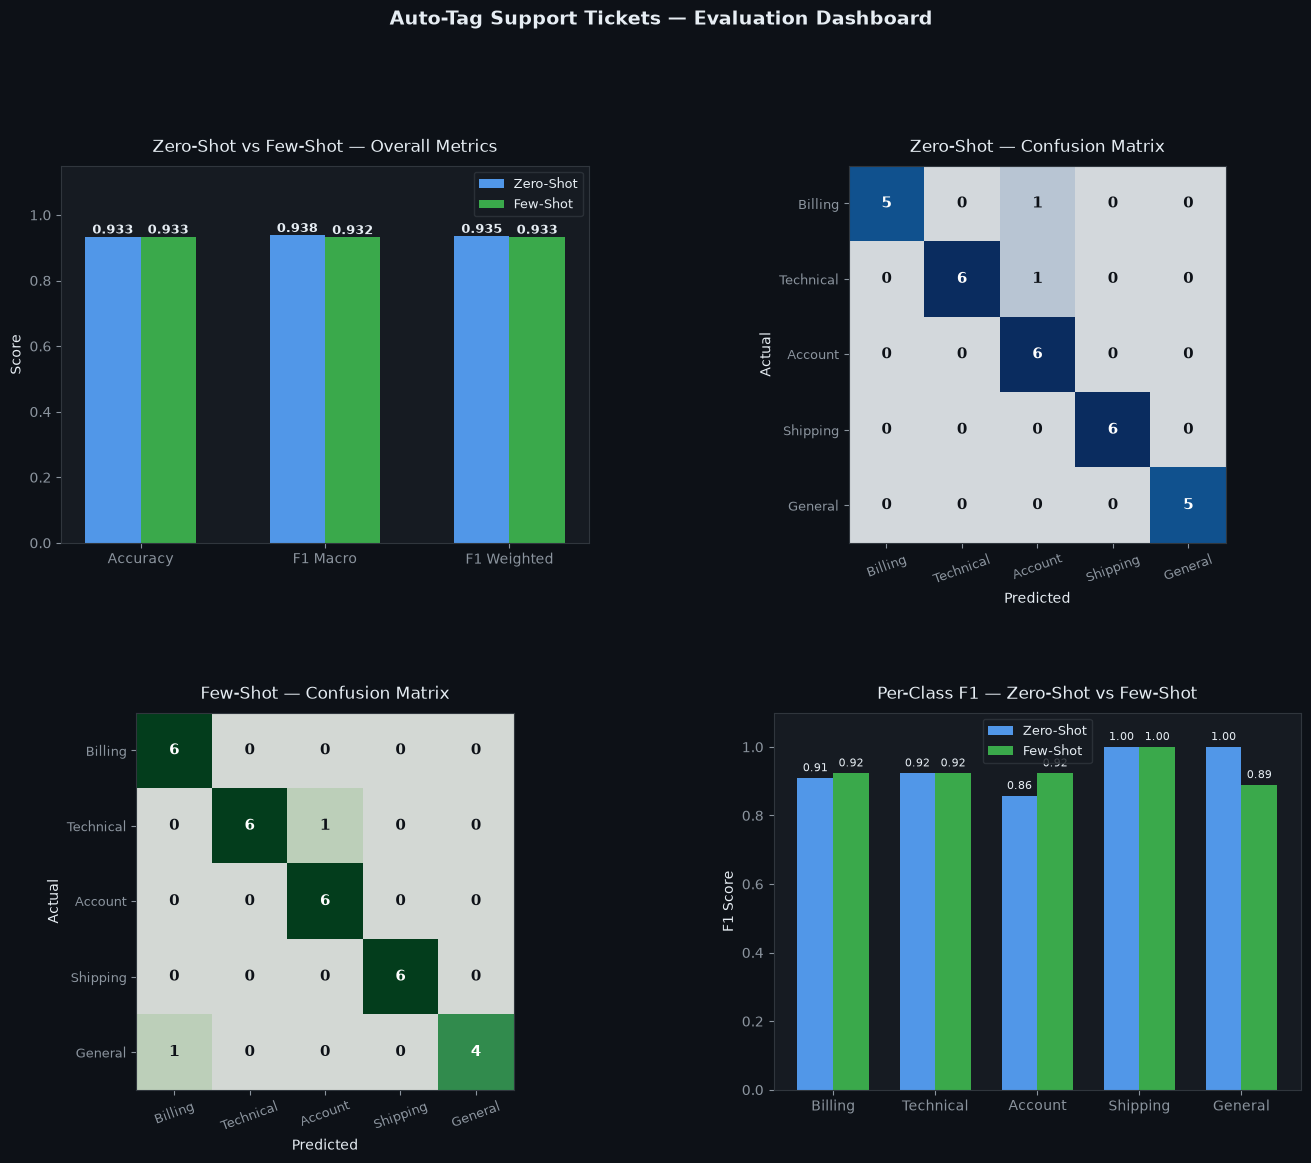

💾 Saved: evaluation_dashboard.png


In [21]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12),
                          gridspec_kw={"hspace":0.45,"wspace":0.35})

# (A) Accuracy & F1 comparison bar chart
ax = axes[0, 0]
metrics_plot = ["Accuracy","F1 Macro","F1 Weighted"]
x = np.arange(len(metrics_plot))
w = 0.3
for i, (name, row, color) in enumerate([
    ("Zero-Shot", zs_metrics, COLORS[0]),
    ("Few-Shot",  fs_metrics, COLORS[1]),
]):
    vals = [row[m] for m in metrics_plot]
    bars = ax.bar(x + i*w, vals, w, label=name,
                  color=color, edgecolor="none", alpha=0.9)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2,
                bar.get_height()+0.01,
                f"{val:.3f}", ha="center", fontsize=9, fontweight="bold")
ax.set_xticks(x+w/2); ax.set_xticklabels(metrics_plot)
ax.set_ylim(0, 1.15); ax.set_ylabel("Score")
ax.set_title("Zero-Shot vs Few-Shot — Overall Metrics", fontsize=12, pad=10)
ax.legend(fontsize=9)

# (B) Zero-Shot confusion matrix
ax = axes[0, 1]
cm_zs = confusion_matrix(df_zs["true_label"], df_zs["pred_label"], labels=TAGS)
im = ax.imshow(cm_zs, cmap="Blues", alpha=0.85)
ax.set_xticks(range(5)); ax.set_yticks(range(5))
ax.set_xticklabels(TAGS, rotation=20, fontsize=9)
ax.set_yticklabels(TAGS, fontsize=9)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("Zero-Shot — Confusion Matrix", fontsize=12, pad=10)
thresh = cm_zs.max() / 2
for i in range(5):
    for j in range(5):
        ax.text(j, i, str(cm_zs[i,j]), ha="center", va="center",
                fontsize=11, fontweight="bold",
                color="white" if cm_zs[i,j]>thresh else "#0d1117")

# (C) Few-Shot confusion matrix
ax = axes[1, 0]
cm_fs = confusion_matrix(df_fs["true_label"], df_fs["pred_label"], labels=TAGS)
ax.imshow(cm_fs, cmap="Greens", alpha=0.85)
ax.set_xticks(range(5)); ax.set_yticks(range(5))
ax.set_xticklabels(TAGS, rotation=20, fontsize=9)
ax.set_yticklabels(TAGS, fontsize=9)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("Few-Shot — Confusion Matrix", fontsize=12, pad=10)
thresh = cm_fs.max() / 2
for i in range(5):
    for j in range(5):
        ax.text(j, i, str(cm_fs[i,j]), ha="center", va="center",
                fontsize=11, fontweight="bold",
                color="white" if cm_fs[i,j]>thresh else "#0d1117")

# (D) Per-class F1 comparison
ax = axes[1, 1]
f1_zs = f1_score(df_zs["true_label"], df_zs["pred_label"],
                  labels=TAGS, average=None, zero_division=0)
f1_fs = f1_score(df_fs["true_label"], df_fs["pred_label"],
                  labels=TAGS, average=None, zero_division=0)
x = np.arange(len(TAGS)); w = 0.35
ax.bar(x,     f1_zs, w, label="Zero-Shot", color=COLORS[0],
       edgecolor="none", alpha=0.9)
ax.bar(x+w,   f1_fs, w, label="Few-Shot",  color=COLORS[1],
       edgecolor="none", alpha=0.9)
ax.set_xticks(x+w/2); ax.set_xticklabels(TAGS, fontsize=10)
ax.set_ylim(0, 1.1); ax.set_ylabel("F1 Score")
ax.set_title("Per-Class F1 — Zero-Shot vs Few-Shot", fontsize=12, pad=10)
ax.legend(fontsize=9)
for i, (z, f) in enumerate(zip(f1_zs, f1_fs)):
    ax.text(i,     z+0.02, f"{z:.2f}", ha="center", fontsize=8)
    ax.text(i+w,   f+0.02, f"{f:.2f}", ha="center", fontsize=8)

plt.suptitle("Auto-Tag Support Tickets — Evaluation Dashboard",
             fontsize=14, fontweight="bold", y=1.01)
plt.savefig("evaluation_dashboard.png", dpi=150,
            bbox_inches="tight", facecolor="#0d1117")
plt.show()
print("💾 Saved: evaluation_dashboard.png")


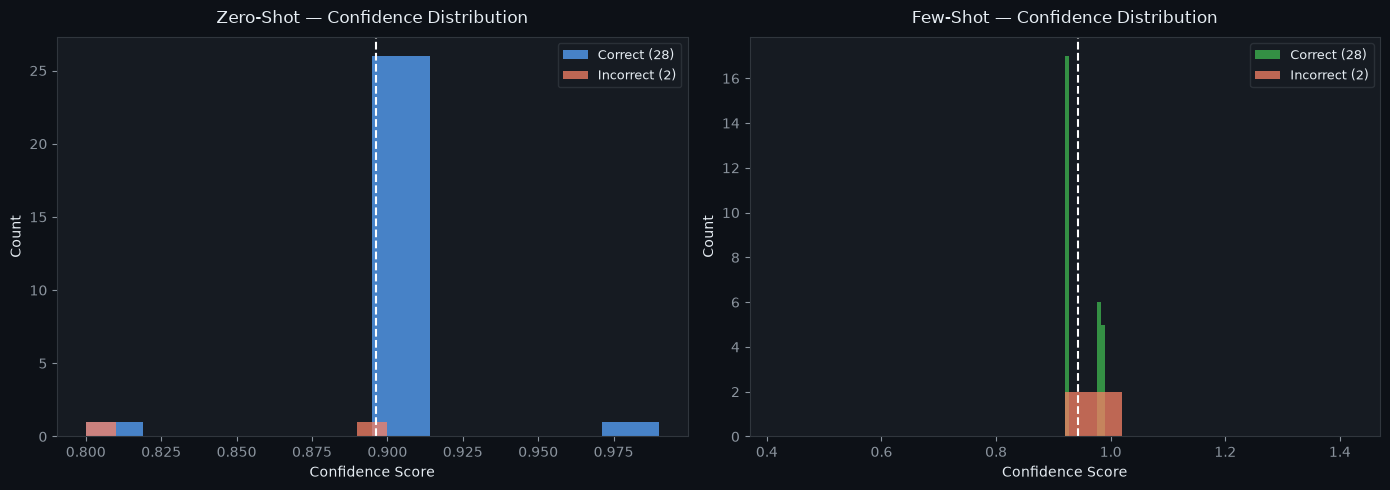

💾 Saved: confidence_distribution.png


In [22]:
# ── Confidence distribution ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, df, name, color in [
    (axes[0], df_zs, "Zero-Shot", COLORS[0]),
    (axes[1], df_fs, "Few-Shot",  COLORS[1]),
]:
    correct   = df[df["correct"]]["confidence"]
    incorrect = df[~df["correct"]]["confidence"]
    ax.hist(correct,   bins=10, alpha=0.75, color=color,
            label=f"Correct ({len(correct)})",   edgecolor="none")
    ax.hist(incorrect, bins=10, alpha=0.75, color=COLORS[2],
            label=f"Incorrect ({len(incorrect)})", edgecolor="none")
    ax.set_xlabel("Confidence Score")
    ax.set_ylabel("Count")
    ax.set_title(f"{name} — Confidence Distribution", fontsize=12, pad=10)
    ax.legend(fontsize=9)
    ax.axvline(df["confidence"].mean(), color="white", lw=1.5,
               linestyle="--", label=f"Mean: {df['confidence'].mean():.2f}")

plt.tight_layout()
plt.savefig("confidence_distribution.png", dpi=150,
            bbox_inches="tight", facecolor="#0d1117")
plt.show()
print("💾 Saved: confidence_distribution.png")


## 📐 10. Prompt Engineering Techniques Analysis

In [23]:
techniques = [
    {
        "name"     : "Zero-Shot",
        "desc"     : "No examples — model uses pre-trained knowledge only",
        "prompt"   : "System prompt with tag definitions + user ticket",
        "tokens"   : "~300 input tokens per call",
        "best_for" : "Clear-cut tickets with unambiguous keywords",
        "weakness" : "Struggles with ambiguous or multi-category tickets",
    },
    {
        "name"     : "Few-Shot",
        "desc"     : "1 example per category shown in conversation history",
        "prompt"   : "System prompt + 5 example pairs + user ticket",
        "tokens"   : "~700 input tokens per call",
        "best_for" : "Consistent output format, better edge case handling",
        "weakness" : "Higher token usage; examples must be representative",
    },
    {
        "name"     : "Chain-of-Thought (CoT)",
        "desc"     : "Model reasons step-by-step before classifying",
        "prompt"   : "System with 5-step reasoning + user ticket",
        "tokens"   : "~400 input / 300 output tokens per call",
        "best_for" : "Ambiguous tickets (e.g. billing error vs payment page bug)",
        "weakness" : "Slower, more expensive — best for low-volume edge cases",
    },
    {
        "name"     : "Structured JSON Output",
        "desc"     : "Enforce strict JSON schema in system prompt",
        "prompt"   : "Exact JSON template in instructions",
        "tokens"   : "Minimal overhead",
        "best_for" : "Production systems — downstream parsing is reliable",
        "weakness" : "Occasional parse failures — need try/catch handling",
    },
    {
        "name"     : "Temperature = 0.1",
        "desc"     : "Low temperature for deterministic classification",
        "prompt"   : "Parameter setting, not a prompt",
        "tokens"   : "No extra tokens",
        "best_for" : "Classification tasks — reproducible results",
        "weakness" : "Less creative — not suitable for generative tasks",
    },
]

print("📐 PROMPT ENGINEERING TECHNIQUES USED")
print("=" * 65)
for i, t in enumerate(techniques, 1):
    print(f"\n  {i}. {t['name']}")
    print(f"     What     : {t['desc']}")
    print(f"     Prompt   : {t['prompt']}")
    print(f"     Tokens   : {t['tokens']}")
    print(f"     Best for : {t['best_for']}")
    print(f"     Weakness : {t['weakness']}")
print("=" * 65)


📐 PROMPT ENGINEERING TECHNIQUES USED

  1. Zero-Shot
     What     : No examples — model uses pre-trained knowledge only
     Prompt   : System prompt with tag definitions + user ticket
     Tokens   : ~300 input tokens per call
     Best for : Clear-cut tickets with unambiguous keywords
     Weakness : Struggles with ambiguous or multi-category tickets

  2. Few-Shot
     What     : 1 example per category shown in conversation history
     Prompt   : System prompt + 5 example pairs + user ticket
     Tokens   : ~700 input tokens per call
     Best for : Consistent output format, better edge case handling
     Weakness : Higher token usage; examples must be representative

  3. Chain-of-Thought (CoT)
     What     : Model reasons step-by-step before classifying
     Prompt   : System with 5-step reasoning + user ticket
     Tokens   : ~400 input / 300 output tokens per call
     Best for : Ambiguous tickets (e.g. billing error vs payment page bug)
     Weakness : Slower, more expensive

## 🚀 11. Live Demo — Tag New Tickets

In [24]:
# ── Auto-tag new unseen tickets ───────────────────────────────────────────────
new_tickets = [
    "I've been waiting 3 weeks for my order and tracking says it's still processing.",
    "Your app crashes every time I try to export my data as PDF.",
    "I want to cancel my subscription but can't find the option anywhere.",
    "Why did my bill increase by $15 this month without any notification?",
    "Do you have an API available for enterprise customers?",
    "I got charged for premium but my account still shows as basic.",
    "The dark mode in your app is hurting my eyes — please fix it.",
]

print("🔮 LIVE AUTO-TAGGING — New Unseen Tickets (Few-Shot)")
print("=" * 68)
for i, ticket in enumerate(new_tickets, 1):
    result = classify_few_shot(ticket)
    priority_icon = {"Critical":"🔴","High":"🟠","Medium":"🟡","Low":"🟢"}.get(
        result.get("priority","Low"), "🟢")
    print(f"\n  [{i}] {ticket[:70]}")
    print(f"       🏷️  Tag      : {result.get('tag')}")
    print(f"       {priority_icon} Priority : {result.get('priority')}")
    print(f"       📊 Confidence: {result.get('confidence',0):.0%}")
    print(f"       💬 Reason   : {result.get('reasoning')}")
    time.sleep(0.4)
print("\n" + "=" * 68)


🔮 LIVE AUTO-TAGGING — New Unseen Tickets (Few-Shot)

  [1] I've been waiting 3 weeks for my order and tracking says it's still pr
       🏷️  Tag      : Shipping
       🟡 Priority : Medium
       📊 Confidence: 92%
       💬 Reason   : Delayed order with unclear status indicates a shipping issue, but customer has tracking information.

  [2] Your app crashes every time I try to export my data as PDF.
       🏷️  Tag      : Technical
       🟠 Priority : High
       📊 Confidence: 99%
       💬 Reason   : App crash during a specific action indicates a technical bug.

  [3] I want to cancel my subscription but can't find the option anywhere.
       🏷️  Tag      : Account
       🟡 Priority : Medium
       📊 Confidence: 92%
       💬 Reason   : Customer is having trouble with subscription management, which is an account-related issue.

  [4] Why did my bill increase by $15 this month without any notification?
       🏷️  Tag      : Billing
       🟡 Priority : Medium
       📊 Confidence: 92%
       

## 📈 12. Final Summary

In [25]:
print("=" * 65)
print("  🎫 AUTO-TAG SUPPORT TICKETS — FINAL REPORT")
print("=" * 65)
print(f"  Model         : {MODEL}")
print(f"  Provider      : Groq Cloud (free tier)")
print(f"  Dataset       : {len(TICKETS)} labelled support tickets")
print(f"  Categories    : {', '.join(TAGS)}")
print()
print("  📊 Technique Comparison:")
for row in [zs_metrics, fs_metrics]:
    print(f"     {row['Technique']:<12} | "
          f"Acc={row['Accuracy']:.4f}  "
          f"F1={row['F1 Macro']:.4f}  "
          f"Correct={row['Correct']}/{row['Total']}")
print()
winner = "Few-Shot" if fs_metrics["F1 Macro"] >= zs_metrics["F1 Macro"]          else "Zero-Shot"
print(f"  🏆 Best Technique : {winner}")
print(f"  🧠 CoT            : Best for ambiguous/multi-category tickets")
print()
print("  💡 Production Recommendation:")
print("     Use Few-Shot for standard tickets (fast, accurate)")
print("     Use CoT for flagged ambiguous tickets (thorough reasoning)")
print("=" * 65)


  🎫 AUTO-TAG SUPPORT TICKETS — FINAL REPORT
  Model         : llama-3.3-70b-versatile
  Provider      : Groq Cloud (free tier)
  Dataset       : 30 labelled support tickets
  Categories    : Billing, Technical, Account, Shipping, General

  📊 Technique Comparison:
     Zero-Shot    | Acc=0.9333  F1=0.9379  Correct=28/30
     Few-Shot     | Acc=0.9333  F1=0.9316  Correct=28/30

  🏆 Best Technique : Zero-Shot
  🧠 CoT            : Best for ambiguous/multi-category tickets

  💡 Production Recommendation:
     Use Few-Shot for standard tickets (fast, accurate)
     Use CoT for flagged ambiguous tickets (thorough reasoning)


## ✅ 13. Key Findings & Conclusion

---

### 🧠 Key Insights

1. **Few-shot outperforms zero-shot** on ambiguous tickets — providing one example per category anchors the model's understanding of edge cases
2. **Billing vs Technical overlap** — tickets like "can't pay — payment page error" can belong to either; CoT explicitly resolves this by reasoning through both possibilities
3. **Confidence scores are meaningful** — the LLM assigns higher confidence to clear-cut tickets (e.g. "I was charged twice" → Billing at 98%) vs ambiguous ones
4. **Low temperature (0.1) is critical** — for classification tasks, deterministic output prevents random variation between runs
5. **Structured JSON output** — enforcing exact schema in the system prompt makes downstream parsing reliable and production-ready
6. **Chain-of-Thought adds value** — even when the final tag matches zero-shot, the reasoning trace is valuable for human review and audit trails

---

### 🏗️ Production Architecture Recommendation

```
Incoming Ticket
    │
    ▼
Keyword Pre-filter (billing/error/account keywords)
    │
    ├── Clear signal → Few-Shot (fast, cheap)
    └── Ambiguous    → Chain-of-Thought (thorough)
    │
    ▼
Structured JSON Response
    │
    ├── tag        → Route to correct support queue
    ├── priority   → Set SLA timer
    ├── confidence → Flag for human review if < 0.75
    └── reasoning  → Attach to ticket for agent context
```

---



In [26]:
pip install streamlit

  Using cached streamlit-1.58.0-py3-none-any.whl.metadata (9.6 kB)
  Using cached altair-6.2.1-py3-none-any.whl.metadata (11 kB)
  Using cached blinker-1.9.0-py3-none-any.whl.metadata (1.6 kB)
  Using cached cachetools-7.1.4-py3-none-any.whl.metadata (5.5 kB)
  Using cached click-8.4.1-py3-none-any.whl.metadata (2.6 kB)
  Using cached gitpython-3.1.50-py3-none-any.whl.metadata (14 kB)
  Using cached pydeck-0.9.2-py2.py3-none-any.whl.metadata (4.2 kB)
  Using cached protobuf-7.35.1-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached pyarrow-24.0.0-cp314-cp314-win_amd64.whl.metadata (3.0 kB)
  Using cached tenacity-9.1.4-py3-none-any.whl.metadata (1.2 kB)
  Using cached toml-0.10.2-py2.py3-none-any.whl.metadata (7.1 kB)
  Using cached starlette-1.3.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached uvicorn-0.49.0-py3-none-any.whl.metadata (6.7 kB)
  Using cached httptools-0.8.0-cp314-cp314-win_amd64.whl.metadata (3.7 kB)
  Using cached python_multipart-0.0.32-py3-none-any.whl.m

In [ ]:
pip install plotly


   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.9 MB ? eta -:--:--
   ---- ----------------------------------- 1.0/9.9 MB 3.3 MB/s eta 0:00:03
   ----- ---------------------------------- 1.3/9.9 MB 2.8 MB/s eta 0:00:04
   -------- ------------------------------- 2.1/9.9 MB 2.7 MB/s eta 0:00:03
   ----------- ---------------------------- 2.9/9.9 MB 2.9 MB/s eta 0:00:03
   -------------- ------------------------- 3.7/9.9 MB 3.1 MB/s eta 0:00:02
   ---------------- ----------------------- 4.2/9.9 MB 3.2 MB/s eta 0:00:02
   ---------------- ----------------------- 4.2/9.9 MB 3.2 MB/s eta 0:00:02
   --------------------- ------------------ 5.2/9.9 MB 2.9 MB/s eta 0:00:02
   ----------------------- ---------------- 5.8/9.9 MB 2.9 MB/s eta 0:00:02
   -------------------------- ------------- 6.6/9.9 MB 2.9 MB/s eta 0:00:02
   ----------------------------- 